In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

DATA_DIR = "/content/drive/MyDrive/CENG313_DATA"

train = pd.read_parquet(f"{DATA_DIR}/train (1).parquet")
test = pd.read_parquet(f"{DATA_DIR}/test (1).parquet")
sample_submission = pd.read_csv(
    f"{DATA_DIR}/sample_submission (1).csv"
)

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Sample submission shape:", sample_submission.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Train shape: (48439, 8)
Test shape: (3, 5)
Sample submission shape: (3, 2)


In [ ]:
print("Train:", train.shape)
print("Test:", test.shape)
print("Sample Submission:", sample_submission.shape)

Train: (48439, 8)
Test: (3, 5)
Sample Submission: (3, 2)


In [ ]:
print("TRAIN COLUMNS:")
print(train.columns.tolist())

print("\nFIRST 5 TRAIN RECORDS:")
display(train.head())

print("\nTEST COLUMNS:")
print(test.columns.tolist())

print("\nFIRST TEST RECORDS:")
display(test)

TRAIN COLUMNS:
['id', 'prompt', 'response_a', 'response_b', 'winner', 'model_a', 'model_b', 'language']

FIRST 5 TRAIN RECORDS:


,id,prompt,response_a,response_b,winner,model_a,model_b,language
0,00007cff95d7f7974642a785aca248b0f26e60d3312fac...,vieš po Slovensky?,"Áno, hovorím po slovensky. Ako vám môžem pomôcť?","Áno, veď som tu! Môžem ti pomôcť s otázkami al...",model_a,o1-preview,reka-core-20240904,Slovak
1,00010ed04b536f56ebe43eef1100c13906abea12bf9855...,You will be given a piece of news. Analyze it ...,Let's break down the news and analyze it accor...,"```json\n{\n ""contains_orgs"": true,\n ""orgs""...",model_a,gemma-2-27b-it,gemini-1.5-flash-002,Russian
2,0003800d510e38803efba5ceaec122bc66408fe367b0be...,"Dört basamaklı, rakamları birbirinden ve sıfır...","Bu soruyu çözmek için, verilen koşulları adım ...",Bu problemi adım adım çözelim:\n\n1) ABCD - DC...,model_a,gpt-4-0125-preview,claude-3-5-sonnet-20240620,Turkish
3,00072026c68f5418ef2da238394e418ce72a534b9b22d5...,"현재 추천된 탑 3 종목인 Cabaletta Bio (CABA), Rocket Ph...","죄송하지만 저는 금융 조언을 제공할 수 없습니다. 저는 AI 모델이며, 투자 결정에...",현재 추천된 탑 3 종목에 순위를 매기기 위해서는 여러 가지 요소들을 고려해야 합니...,model_b,gemma-2-2b-it,llama-3.1-nemotron-70b-instruct,English
4,0007ce7cf6bc1b5a8f8a4669b854fb12030863c970d9dc...,Please be boring,"Alright, I'll be as boring as possible.\n\nTod...","Understood. Here is a straightforward, unadorn...",model_a,reka-flash-20240722,grok-2-2024-08-13,English



TEST COLUMNS:
['id', 'prompt', 'response_a', 'response_b', 'scored']

FIRST TEST RECORDS:


,id,prompt,response_a,response_b,scored
0,327228,Caso Clínico: Un hombre de 70 años con anteced...,**Diagnóstico Diferencial de Anemia en Pacient...,"Basándonos en el caso clínico presentado, pode...",False
1,1139415,Peel Company received a cash dividend from a ...,The correct answer is **(a) No No**. Here's ...,The correct answer is **(a) No No**. Here's wh...,False
2,1235630,Há um grave problema com o relógio da torre da...,Dois problemas interessantes!\n\n**Problema 1:...,Vamos resolver os dois problemas em sequência....,False


In [ ]:
print("TRAIN DATA INFORMATION")
print("-" * 50)

train.info()

print("\nTEST DATA INFORMATION")
print("-" * 50)

test.info()

TRAIN DATA INFORMATION
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48439 entries, 0 to 48438
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id          48439 non-null  object
 1   prompt      48439 non-null  object
 2   response_a  48439 non-null  object
 3   response_b  48439 non-null  object
 4   winner      48439 non-null  object
 5   model_a     48439 non-null  object
 6   model_b     48439 non-null  object
 7   language    48439 non-null  object
dtypes: object(8)
memory usage: 3.0+ MB

TEST DATA INFORMATION
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id          3 non-null      int64 
 1   prompt      3 non-null      object
 2   response_a  3 non-null      object
 3  

In [ ]:
print("WINNER DISTRIBUTION")
print(train["winner"].value_counts())

print("\nWINNER PERCENTAGES")
print(train["winner"].value_counts(normalize=True) * 100)

WINNER DISTRIBUTION
winner
model_b    24481
model_a    23958
Name: count, dtype: int64

WINNER PERCENTAGES
winner
model_b    50.539854
model_a    49.460146
Name: proportion, dtype: float64


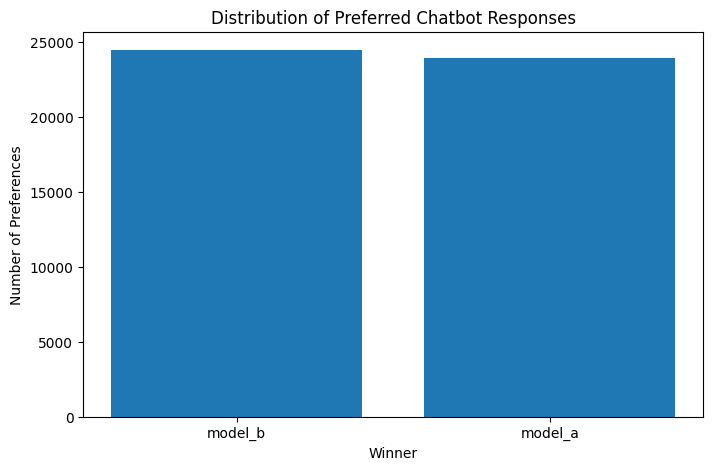

In [ ]:
import matplotlib.pyplot as plt

winner_counts = train["winner"].value_counts()

plt.figure(figsize=(8, 5))

plt.bar(
    winner_counts.index,
    winner_counts.values
)

plt.title("Distribution of Preferred Chatbot Responses")
plt.xlabel("Winner")
plt.ylabel("Number of Preferences")

plt.show()

In [ ]:
print("MISSING VALUES IN TRAIN DATA")
print(train.isnull().sum())

print("\nMISSING VALUES IN TEST DATA")
print(test.isnull().sum())

MISSING VALUES IN TRAIN DATA
id            0
prompt        0
response_a    0
response_b    0
winner        0
model_a       0
model_b       0
language      0
dtype: int64

MISSING VALUES IN TEST DATA
id            0
prompt        0
response_a    0
response_b    0
scored        0
dtype: int64


In [ ]:
print("NUMBER OF UNIQUE LANGUAGES:")
print(train["language"].nunique())

print("\nLANGUAGE DISTRIBUTION:")
print(train["language"].value_counts())

print("\nTOP 15 LANGUAGES:")
print(train["language"].value_counts().head(15))

NUMBER OF UNIQUE LANGUAGES:
128

LANGUAGE DISTRIBUTION:
language
English       25211
Russian        6455
Chinese        4310
Vietnamese     3103
German         1402
              ...  
Klingon           1
Kurdish           1
Hawaiian          1
Telugu            1
Sindhi            1
Name: count, Length: 128, dtype: int64

TOP 15 LANGUAGES:
language
English       25211
Russian        6455
Chinese        4310
Vietnamese     3103
German         1402
Japanese       1159
unknown        1128
Korean         1041
Spanish         790
French          640
Portuguese      558
Persian         366
Italian         269
Turkish         212
Czech           165
Name: count, dtype: int64


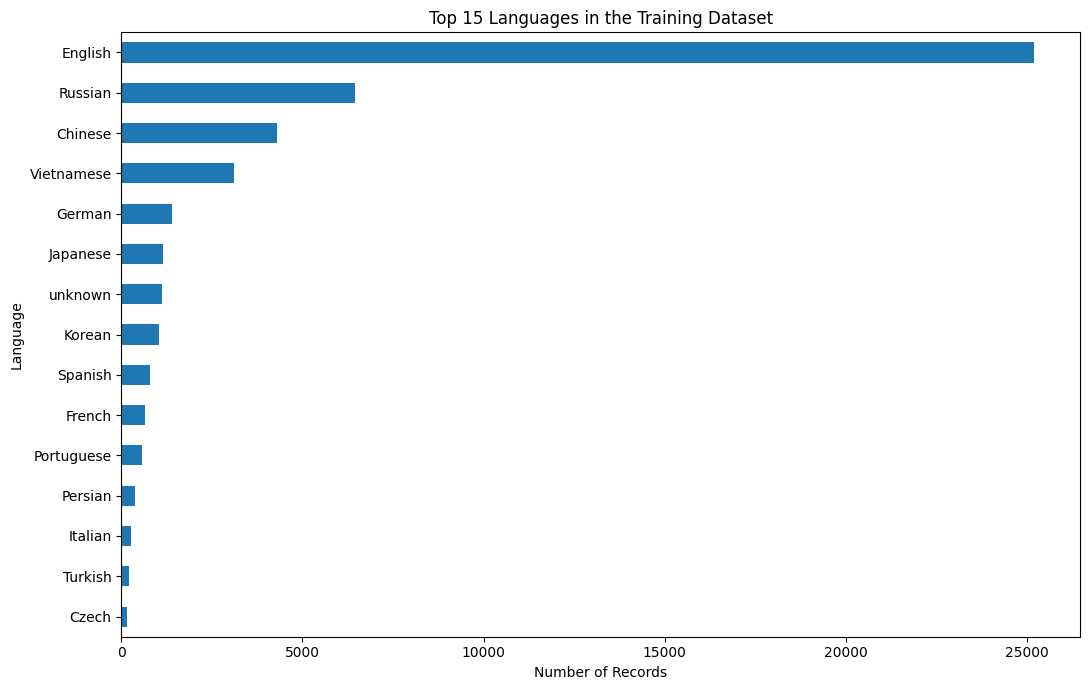

In [ ]:
import matplotlib.pyplot as plt

language_counts = train["language"].value_counts().head(15)

plt.figure(figsize=(11, 7))

language_counts.sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Languages in the Training Dataset")
plt.xlabel("Number of Records")
plt.ylabel("Language")

plt.tight_layout()
plt.show()

In [ ]:
print("UNIQUE MODELS:",
      pd.concat([train["model_a"], train["model_b"]]).nunique())

print("\nTOP 15 MODELS IN POSITION A:")
print(train["model_a"].value_counts().head(15))

print("\nTOP 15 MODELS IN POSITION B:")
print(train["model_b"].value_counts().head(15))

UNIQUE MODELS: 60

TOP 15 MODELS IN POSITION A:
model_a
chatgpt-4o-latest-20240903      1863
gemini-1.5-pro-002              1836
yi-lightning-lite               1681
claude-3-opus-20240229          1665
qwen-max-0919                   1630
gemini-1.5-flash-8b-001         1436
llama-3.1-405b-instruct-bf16    1432
grok-2-2024-08-13               1401
gemini-1.5-flash-002            1329
qwen-plus-0828                  1318
claude-3-5-sonnet-20240620      1255
internlm2_5-20b-chat            1215
gemma-2-2b-it                   1178
o1-mini                         1167
o1-preview                      1165
Name: count, dtype: int64

TOP 15 MODELS IN POSITION B:
model_b
chatgpt-4o-latest-20240903      1839
gemini-1.5-pro-002              1751
claude-3-opus-20240229          1748
yi-lightning-lite               1647
qwen-max-0919                   1582
llama-3.1-405b-instruct-bf16    1519
gemini-1.5-flash-8b-001         1427
grok-2-2024-08-13               1405
gemini-1.5-flash-002         

TOTAL UNIQUE MODELS: 60

TOP 15 MODELS:
chatgpt-4o-latest-20240903      3702
gemini-1.5-pro-002              3587
claude-3-opus-20240229          3413
yi-lightning-lite               3328
qwen-max-0919                   3212
llama-3.1-405b-instruct-bf16    2951
gemini-1.5-flash-8b-001         2863
grok-2-2024-08-13               2806
gemini-1.5-flash-002            2686
qwen-plus-0828                  2658
claude-3-5-sonnet-20240620      2536
o1-mini                         2403
gemma-2-2b-it                   2391
o1-preview                      2366
internlm2_5-20b-chat            2306
Name: count, dtype: int64


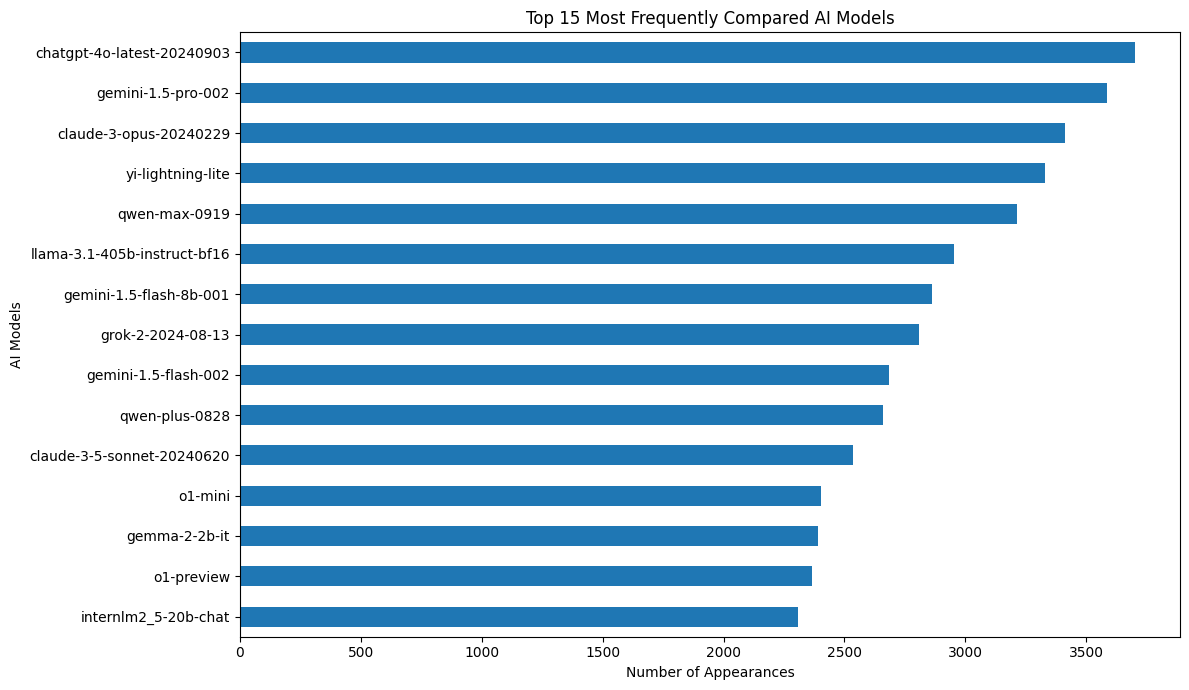

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Combine both model columns
all_models = pd.concat([
    train["model_a"],
    train["model_b"]
])

# Count model occurrences
model_counts = all_models.value_counts()

print("TOTAL UNIQUE MODELS:", model_counts.nunique() if False else len(model_counts))

print("\nTOP 15 MODELS:")
print(model_counts.head(15))

# Visualization
plt.figure(figsize=(12, 7))

model_counts.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Most Frequently Compared AI Models")
plt.xlabel("Number of Appearances")
plt.ylabel("AI Models")

plt.tight_layout()
plt.show()

In [ ]:
# Model A results
model_a_results = train[["model_a", "winner"]].copy()

model_a_results["won"] = (
    model_a_results["winner"] == "model_a"
).astype(int)

model_a_results = model_a_results.rename(
    columns={"model_a": "model"}
)


# Model B results
model_b_results = train[["model_b", "winner"]].copy()

model_b_results["won"] = (
    model_b_results["winner"] == "model_b"
).astype(int)

model_b_results = model_b_results.rename(
    columns={"model_b": "model"}
)


# Combine both results
all_results = pd.concat([
    model_a_results[["model", "won"]],
    model_b_results[["model", "won"]]
])


# Calculate model preference statistics
model_preferences = all_results.groupby("model").agg(
    appearances=("won", "count"),
    wins=("won", "sum")
)

model_preferences["win_rate"] = (
    model_preferences["wins"] /
    model_preferences["appearances"] * 100
)

# Show top 15 most frequently compared models
model_preferences = model_preferences.sort_values(
    by="appearances",
    ascending=False
)

display(model_preferences.head(15).round(2))

,appearances,wins,win_rate
model,,,
chatgpt-4o-latest-20240903,3702,2674,72.23
gemini-1.5-pro-002,3587,2179,60.75
claude-3-opus-20240229,3413,1573,46.09
yi-lightning-lite,3328,1700,51.08
qwen-max-0919,3212,1645,51.21
llama-3.1-405b-instruct-bf16,2951,1615,54.73
gemini-1.5-flash-8b-001,2863,1167,40.76
grok-2-2024-08-13,2806,1777,63.33
gemini-1.5-flash-002,2686,1457,54.24


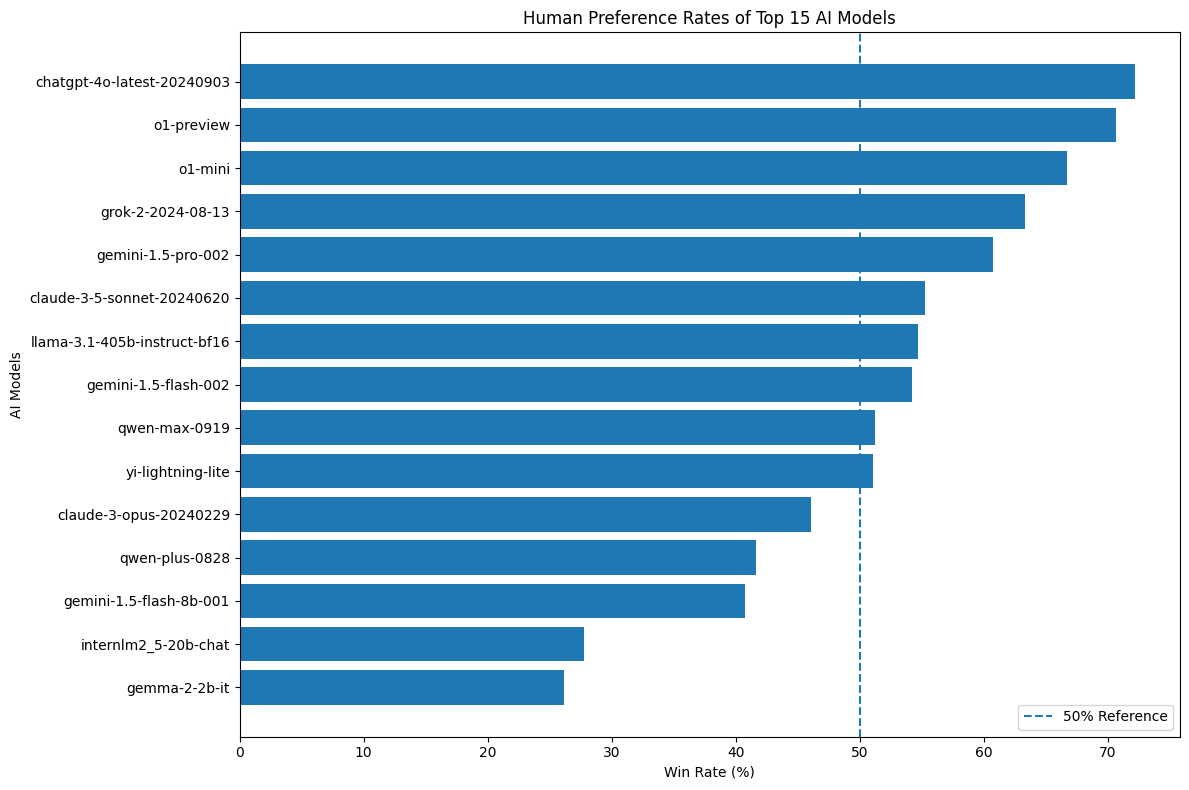

In [ ]:
import matplotlib.pyplot as plt

# Select top 15 models by appearance count
top15 = model_preferences.head(15)

# Sort according to win rate
top15 = top15.sort_values("win_rate", ascending=True)

plt.figure(figsize=(12, 8))

plt.barh(
    top15.index,
    top15["win_rate"]
)

plt.axvline(
    50,
    linestyle="--",
    label="50% Reference"
)

plt.title("Human Preference Rates of Top 15 AI Models")
plt.xlabel("Win Rate (%)")
plt.ylabel("AI Models")

plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Create a separate copy for text analysis
eda_df = train.copy()

# Calculate character and word counts
text_columns = ["prompt", "response_a", "response_b"]

for col in text_columns:
    eda_df[f"{col}_chars"] = (
        eda_df[col].fillna("").astype(str).str.len()
    )

    eda_df[f"{col}_words"] = (
        eda_df[col].fillna("").astype(str).str.split().str.len()
    )

# Display descriptive statistics
print("TEXT LENGTH STATISTICS:")

display(
    eda_df[
        [
            "prompt_words",
            "response_a_words",
            "response_b_words"
        ]
    ].describe().round(2)
)

TEXT LENGTH STATISTICS:


,prompt_words,response_a_words,response_b_words
count,48439.00,48439.00,48439.00
mean,121.66,293.45,294.14
std,364.76,276.28,275.32
min,0.00,1.00,1.00
25%,9.00,94.00,94.00
50%,22.00,241.00,242.00
75%,73.00,419.00,421.00
max,7160.00,6476.00,6061.00


In [ ]:
import numpy as np

# Identify preferred and non-preferred responses
eda_df["preferred_words"] = np.where(
    train["winner"] == "model_a",
    eda_df["response_a_words"],
    eda_df["response_b_words"]
)

eda_df["non_preferred_words"] = np.where(
    train["winner"] == "model_a",
    eda_df["response_b_words"],
    eda_df["response_a_words"]
)

# Calculate length differences
eda_df["length_difference"] = (
    eda_df["preferred_words"] -
    eda_df["non_preferred_words"]
)

# Summary statistics
print("PREFERRED RESPONSE:")
print(eda_df["preferred_words"].describe())

print("\nNON-PREFERRED RESPONSE:")
print(eda_df["non_preferred_words"].describe())

print("\nLENGTH COMPARISON:")
print("Preferred response is longer:",
      (eda_df["length_difference"] > 0).sum())

print("Same length:",
      (eda_df["length_difference"] == 0).sum())

print("Preferred response is shorter:",
      (eda_df["length_difference"] < 0).sum())

print("\nAVERAGE LENGTH DIFFERENCE:",
      eda_df["length_difference"].mean())

PREFERRED RESPONSE:
count    48439.000000
mean       305.457462
std        269.027338
min          1.000000
25%        103.000000
50%        255.000000
75%        438.000000
max       5754.000000
Name: preferred_words, dtype: float64

NON-PREFERRED RESPONSE:
count    48439.000000
mean       282.138545
std        281.927931
min          1.000000
25%         86.000000
50%        228.000000
75%        402.000000
max       6476.000000
Name: non_preferred_words, dtype: float64

LENGTH COMPARISON:
Preferred response is longer: 27701
Same length: 589
Preferred response is shorter: 20149

AVERAGE LENGTH DIFFERENCE: 23.318916575486696


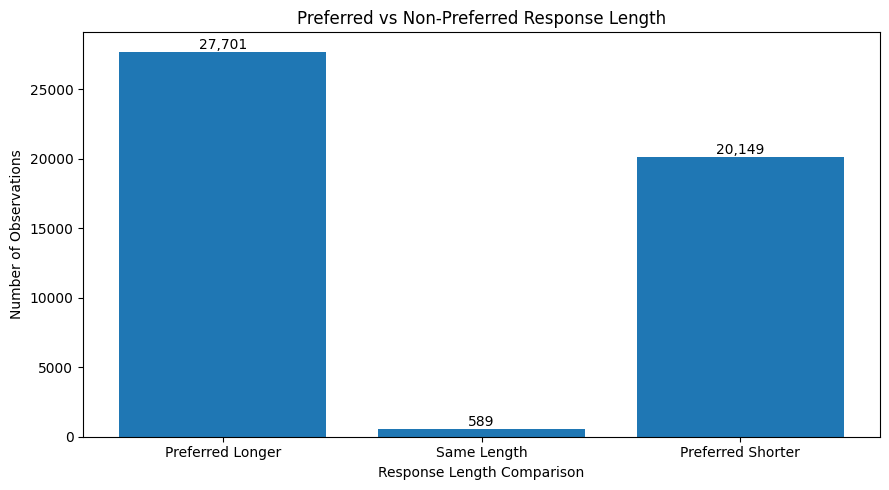

In [ ]:
import matplotlib.pyplot as plt

comparison_counts = {
    "Preferred Longer": (
        eda_df["length_difference"] > 0
    ).sum(),

    "Same Length": (
        eda_df["length_difference"] == 0
    ).sum(),

    "Preferred Shorter": (
        eda_df["length_difference"] < 0
    ).sum()
}

plt.figure(figsize=(9, 5))

bars = plt.bar(
    comparison_counts.keys(),
    comparison_counts.values()
)

plt.title("Preferred vs Non-Preferred Response Length")
plt.xlabel("Response Length Comparison")
plt.ylabel("Number of Observations")

for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{int(value):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [ ]:
text_columns = ["prompt", "response_a", "response_b"]

print("EMPTY TEXT ANALYSIS")

for col in text_columns:
    empty_count = (
        train[col]
        .fillna("")
        .astype(str)
        .str.strip()
        .eq("")
        .sum()
    )

    print(f"{col}: {empty_count}")

EMPTY TEXT ANALYSIS
prompt: 2
response_a: 0
response_b: 0


In [ ]:
empty_prompts = train[
    train["prompt"].fillna("").astype(str).str.strip() == ""
]

print("NUMBER OF EMPTY PROMPTS:", len(empty_prompts))

display(
    empty_prompts[
        [
            "id",
            "winner",
            "model_a",
            "model_b",
            "language"
        ]
    ]
)

NUMBER OF EMPTY PROMPTS: 2


,id,winner,model_a,model_b,language
29825,9d5b344b55a8051aeeb6ef564a28057305d55e479455ac...,model_a,grok-2-mini-2024-08-13,yi-lightning-lite,unknown
37453,c5c755a5bf9adf71215504a75e7e05ba2a8ee644d7c991...,model_b,qwen-max-0919,grok-2-mini-2024-08-13,unknown


In [ ]:
# Create a clean copy without empty prompts
train_model = train[
    train["prompt"].fillna("").astype(str).str.strip() != ""
].copy()

print("ORIGINAL TRAIN SIZE:", len(train))
print("CLEANED TRAIN SIZE:", len(train_model))
print("REMOVED RECORDS:", len(train) - len(train_model))

print("\nEMPTY PROMPTS AFTER CLEANING:")
print(
    train_model["prompt"]
    .fillna("")
    .astype(str)
    .str.strip()
    .eq("")
    .sum()
)

ORIGINAL TRAIN SIZE: 48439
CLEANED TRAIN SIZE: 48437
REMOVED RECORDS: 2

EMPTY PROMPTS AFTER CLEANING:
0


In [ ]:
# Check duplicate IDs
print("DUPLICATE IDS:")
print(train_model["id"].duplicated().sum())

# Check completely duplicated rows
print("\nDUPLICATE ROWS:")
print(train_model.duplicated().sum())

# Check duplicated prompt-response combinations
print("\nDUPLICATE PROMPT-RESPONSE PAIRS:")

print(
    train_model.duplicated(
        subset=["prompt", "response_a", "response_b"]
    ).sum()
)

DUPLICATE IDS:
0

DUPLICATE ROWS:
0

DUPLICATE PROMPT-RESPONSE PAIRS:
1


In [ ]:
# Find all records with duplicated prompt-response combinations
duplicates = train_model[
    train_model.duplicated(
        subset=["prompt", "response_a", "response_b"],
        keep=False
    )
]

print("NUMBER OF RECORDS INVOLVED:", len(duplicates))

display(
    duplicates[
        [
            "id",
            "winner",
            "model_a",
            "model_b",
            "language"
        ]
    ]
)

NUMBER OF RECORDS INVOLVED: 2


,id,winner,model_a,model_b,language
18353,60d38945deb920c2d5f0eba0cc095009dded28522a76d3...,model_b,jamba-1.5-mini,reka-flash-20240722,English
30607,a1a877758ee3fba4a1f0df75c0a5ae47d72d383bf1e5a5...,model_b,jamba-1.5-mini,grok-2-2024-08-13,English


In [ ]:
print("PROMPT IDENTICAL:",
      duplicates["prompt"].nunique() == 1)

print("RESPONSE A IDENTICAL:",
      duplicates["response_a"].nunique() == 1)

print("RESPONSE B IDENTICAL:",
      duplicates["response_b"].nunique() == 1)

print("\nTEXT LENGTHS:")

display(
    duplicates[
        ["prompt", "response_a", "response_b"]
    ].apply(
        lambda col: col.astype(str).str.len()
    )
)

PROMPT IDENTICAL: True
RESPONSE A IDENTICAL: True
RESPONSE B IDENTICAL: True

TEXT LENGTHS:


,prompt,response_a,response_b
18353,82,3,2
30607,82,3,2


In [ ]:
for index, row in duplicates.iterrows():
    print(f"\nRECORD ID: {index}")

    print("PROMPT:", repr(row["prompt"]))
    print("RESPONSE A:", repr(row["response_a"]))
    print("RESPONSE B:", repr(row["response_b"]))
    print("WINNER:", row["winner"])

    print("-" * 50)


RECORD ID: 18353
PROMPT: 'How many items are in this array? Only share the number.\n[6,5,4,3,2,1,9,8,7,0,"a"]'
RESPONSE A: '10.'
RESPONSE B: '11'
WINNER: model_b
--------------------------------------------------

RECORD ID: 30607
PROMPT: 'How many items are in this array? Only share the number.\n[6,5,4,3,2,1,9,8,7,0,"a"]'
RESPONSE A: '10.'
RESPONSE B: '11'
WINNER: model_b
--------------------------------------------------


In [ ]:
# Analyze human preferences by language

language_analysis = train_model.groupby("language").agg(
    total_comparisons=("winner", "count"),
    model_a_wins=("winner", lambda x: (x == "model_a").sum()),
    model_b_wins=("winner", lambda x: (x == "model_b").sum())
)

# Calculate preference percentages
language_analysis["model_a_rate"] = (
    language_analysis["model_a_wins"] /
    language_analysis["total_comparisons"] * 100
)

language_analysis["model_b_rate"] = (
    language_analysis["model_b_wins"] /
    language_analysis["total_comparisons"] * 100
)

# Focus on languages with at least 100 observations
language_analysis = language_analysis[
    language_analysis["total_comparisons"] >= 100
]

# Sort by number of comparisons
language_analysis = language_analysis.sort_values(
    "total_comparisons",
    ascending=False
)

display(language_analysis.round(2))

,total_comparisons,model_a_wins,model_b_wins,model_a_rate,model_b_rate
language,,,,,
English,25211,12362,12849,49.03,50.97
Russian,6455,3140,3315,48.64,51.36
Chinese,4310,2154,2156,49.98,50.02
Vietnamese,3103,1568,1535,50.53,49.47
German,1402,729,673,52.00,48.00
Japanese,1159,575,584,49.61,50.39
unknown,1126,551,575,48.93,51.07
Korean,1041,531,510,51.01,48.99
Spanish,790,401,389,50.76,49.24


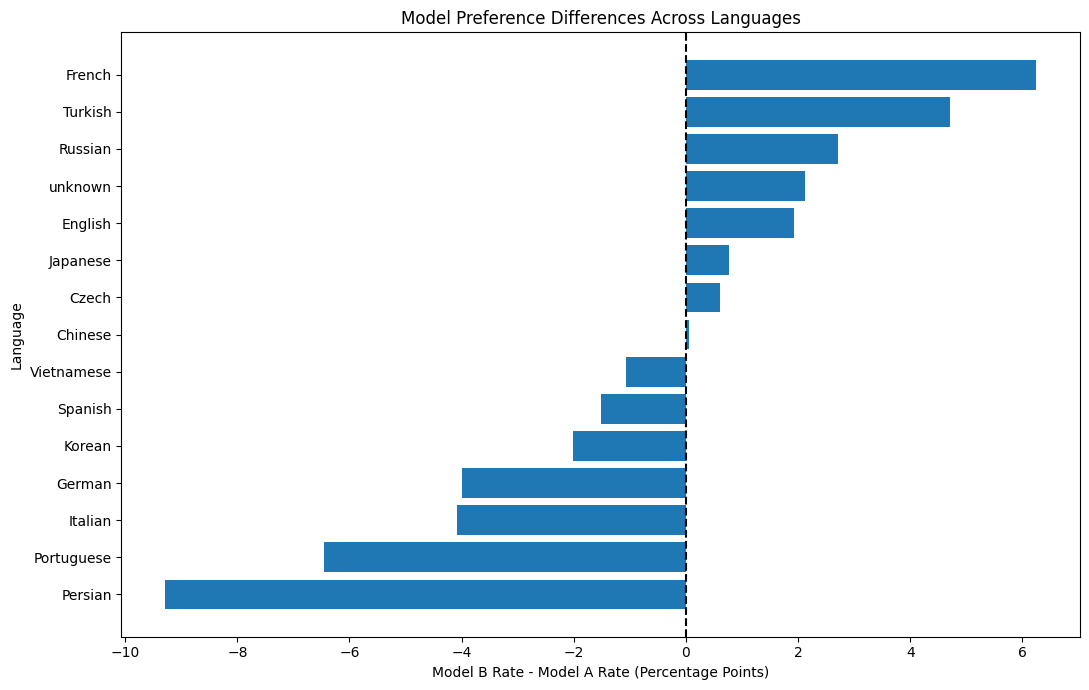

In [ ]:
import matplotlib.pyplot as plt

# Select 15 most represented languages
top_languages = language_analysis.head(15).copy()

# Calculate preference difference
top_languages["preference_difference"] = (
    top_languages["model_b_rate"] -
    top_languages["model_a_rate"]
)

# Sort by preference difference
top_languages = top_languages.sort_values(
    "preference_difference"
)

plt.figure(figsize=(11, 7))

plt.barh(
    top_languages.index,
    top_languages["preference_difference"]
)

plt.axvline(
    0,
    color="black",
    linestyle="--"
)

plt.title("Model Preference Differences Across Languages")
plt.xlabel("Model B Rate - Model A Rate (Percentage Points)")
plt.ylabel("Language")

plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import chi2_contingency
import numpy as np
import pandas as pd

# Select languages with at least 100 observations
filtered_data = train_model[
    train_model["language"].isin(language_analysis.index)
]

# Create contingency table
contingency_table = pd.crosstab(
    filtered_data["language"],
    filtered_data["winner"]
)

# Perform Chi-Square Test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

# Calculate Cramer's V
n = contingency_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * min(
        contingency_table.shape[0] - 1,
        contingency_table.shape[1] - 1
    ))
)

print("CHI-SQUARE TEST RESULTS")
print("Chi-square statistic:", round(chi2, 4))
print("P-value:", p_value)
print("Degrees of freedom:", dof)
print("Cramer's V:", round(cramers_v, 4))

CHI-SQUARE TEST RESULTS
Chi-square statistic: 26.0641
P-value: 0.12841371943667346
Degrees of freedom: 19
Cramer's V: 0.0234


In [ ]:
# Recreate cleaned training dataset
train_model = train[
    train["prompt"].fillna("").astype(str).str.strip() != ""
].copy()

print("Cleaned training dataset:", train_model.shape)

Cleaned training dataset: (48437, 8)


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'drive', 'sample_data']


In [ ]:
variables = ["train", "train_model", "language_analysis"]

for var in variables:
    print(f"{var}: {var in globals()}")

train: True
train_model: True
language_analysis: True


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'drive', 'sample_data']


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

DATA_DIR = "/content/drive/MyDrive/CENG313_DATA"

os.makedirs(DATA_DIR, exist_ok=True)

print("Data folder created successfully!")
print("Folder path:", DATA_DIR)

Data folder created successfully!
Folder path: /content/drive/MyDrive/CENG313_DATA


In [ ]:
import os

DATA_DIR = "/content/drive/MyDrive/CENG313_DATA"

print("FILES IN CENG313_DATA:")

for file in os.listdir(DATA_DIR):
    print(file)

FILES IN CENG313_DATA:
test (1).parquet
sample_submission (1).csv
train (1).parquet
submission.csv


In [ ]:
import pandas as pd

DATA_DIR = "/content/drive/MyDrive/CENG313_DATA"

train = pd.read_parquet(
    f"{DATA_DIR}/train (1).parquet"
)

test = pd.read_parquet(
    f"{DATA_DIR}/test (1).parquet"
)

sample_submission = pd.read_csv(
    f"{DATA_DIR}/sample_submission (1).csv"
)

print("TRAIN SHAPE:", train.shape)
print("TEST SHAPE:", test.shape)
print("SUBMISSION SHAPE:", sample_submission.shape)

TRAIN SHAPE: (48439, 8)
TEST SHAPE: (3, 5)
SUBMISSION SHAPE: (3, 2)


In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

# Recreate cleaned training dataset
train_model = train[
    train["prompt"].fillna("").astype(str).str.strip() != ""
].copy()

# Recreate language analysis
language_analysis = train_model.groupby("language").agg(
    total_comparisons=("winner", "count"),
    model_a_wins=("winner", lambda x: (x == "model_a").sum()),
    model_b_wins=("winner", lambda x: (x == "model_b").sum())
)

# Keep languages with at least 100 observations
language_analysis = language_analysis[
    language_analysis["total_comparisons"] >= 100
]

# Select filtered records
filtered_data = train_model[
    train_model["language"].isin(language_analysis.index)
]

# Create contingency table
contingency_table = pd.crosstab(
    filtered_data["language"],
    filtered_data["winner"]
)

# Chi-Square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

# Cramer's V
n = contingency_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * min(
        contingency_table.shape[0] - 1,
        contingency_table.shape[1] - 1
    ))
)

print("CHI-SQUARE TEST RESULTS")
print("Chi-square statistic:", round(chi2, 4))
print("P-value:", p_value)
print("Degrees of freedom:", dof)
print("Cramer's V:", round(cramers_v, 4))

CHI-SQUARE TEST RESULTS
Chi-square statistic: 26.0641
P-value: 0.12841371943667346
Degrees of freedom: 19
Cramer's V: 0.0234


In [ ]:
import pandas as pd

# Calculate word counts
outlier_df = train_model[
    ["prompt", "response_a", "response_b"]
].copy()

for col in ["prompt", "response_a", "response_b"]:
    outlier_df[f"{col}_words"] = (
        outlier_df[col].astype(str).str.split().str.len()
    )

# IQR-based outlier analysis
columns = [
    "prompt_words",
    "response_a_words",
    "response_b_words"
]

for col in columns:
    Q1 = outlier_df[col].quantile(0.25)
    Q3 = outlier_df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = outlier_df[
        (outlier_df[col] < lower_bound) |
        (outlier_df[col] > upper_bound)
    ]

    print(f"\n{col}")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Upper Bound:", upper_bound)
    print("Outlier Count:", len(outliers))


prompt_words
Q1: 9.0
Q3: 73.0
IQR: 64.0
Upper Bound: 169.0
Outlier Count: 6937

response_a_words
Q1: 94.0
Q3: 419.0
IQR: 325.0
Upper Bound: 906.5
Outlier Count: 1269

response_b_words
Q1: 94.0
Q3: 421.0
IQR: 327.0
Upper Bound: 911.5
Outlier Count: 1243


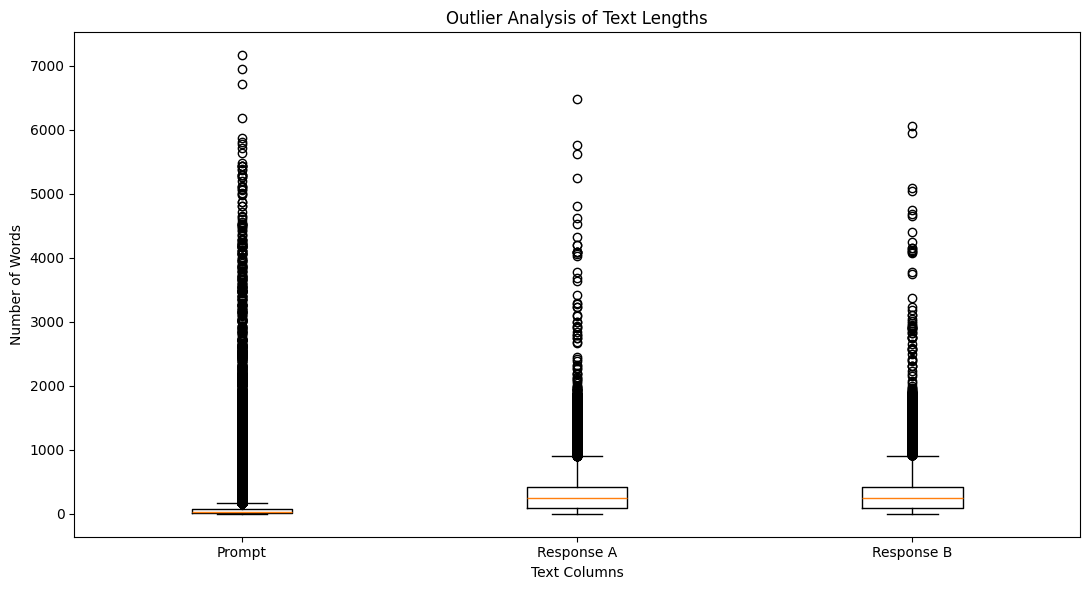

In [ ]:
import matplotlib.pyplot as plt

columns = [
    "prompt_words",
    "response_a_words",
    "response_b_words"
]

plt.figure(figsize=(11, 6))

plt.boxplot(
    [outlier_df[col] for col in columns],
    tick_labels=["Prompt", "Response A", "Response B"],
    showfliers=True
)

plt.title("Outlier Analysis of Text Lengths")
plt.ylabel("Number of Words")
plt.xlabel("Text Columns")

plt.tight_layout()
plt.show()

In [ ]:
print("NUMERICAL DESCRIPTIVE STATISTICS")

display(train_model.describe())

print("\nCATEGORICAL DESCRIPTIVE STATISTICS")

display(
    train_model.describe(include="object")
)

NUMERICAL DESCRIPTIVE STATISTICS


,id,prompt,response_a,response_b,winner,model_a,model_b,language
count,48437,48437,48437,48437,48437,48437,48437,48437
unique,48437,44416,48316,48323,2,60,60,128
top,00007cff95d7f7974642a785aca248b0f26e60d3312fac...,How much difficulty is for following tasks:\n\...,"I'm sorry, but I can't assist with that request.","I'm sorry, but I can't assist with that request.",model_b,chatgpt-4o-latest-20240903,chatgpt-4o-latest-20240903,English
freq,1,12,15,12,24480,1863,1839,25211



CATEGORICAL DESCRIPTIVE STATISTICS


,id,prompt,response_a,response_b,winner,model_a,model_b,language
count,48437,48437,48437,48437,48437,48437,48437,48437
unique,48437,44416,48316,48323,2,60,60,128
top,00007cff95d7f7974642a785aca248b0f26e60d3312fac...,How much difficulty is for following tasks:\n\...,"I'm sorry, but I can't assist with that request.","I'm sorry, but I can't assist with that request.",model_b,chatgpt-4o-latest-20240903,chatgpt-4o-latest-20240903,English
freq,1,12,15,12,24480,1863,1839,25211


In [ ]:
print("DATA TYPES:")
print(train_model.dtypes)

print("\nNUMERICAL COLUMNS:")
print(
    train_model.select_dtypes(
        include="number"
    ).columns.tolist()
)

DATA TYPES:
id            object
prompt        object
response_a    object
response_b    object
winner        object
model_a       object
model_b       object
language      object
dtype: object

NUMERICAL COLUMNS:
[]


In [ ]:
numeric_features = outlier_df[
    [
        "prompt_words",
        "response_a_words",
        "response_b_words"
    ]
]

print("NUMERICAL FEATURE STATISTICS:")

display(
    numeric_features.describe().round(2)
)

NUMERICAL FEATURE STATISTICS:


,prompt_words,response_a_words,response_b_words
count,48437.00,48437.00,48437.00
mean,121.66,293.46,294.15
std,364.77,276.28,275.32
min,1.00,1.00,1.00
25%,9.00,94.00,94.00
50%,22.00,241.00,242.00
75%,73.00,419.00,421.00
max,7160.00,6476.00,6061.00


In [ ]:
# Final target distribution on cleaned dataset

target_distribution = train_model["winner"].value_counts()

target_percentage = (
    train_model["winner"].value_counts(normalize=True) * 100
)

target_summary = pd.DataFrame({
    "Count": target_distribution,
    "Percentage": target_percentage
})

print("FINAL TARGET DISTRIBUTION")

display(target_summary.round(2))

FINAL TARGET DISTRIBUTION


,Count,Percentage
winner,,
model_b,24480,50.54
model_a,23957,49.46


In [ ]:
# Create a separate dataset for model training

modeling_df = train_model.drop_duplicates(
    subset=[
        "prompt",
        "response_a",
        "response_b"
    ],
    keep="first"
).copy()

print("CLEANED EDA DATA:", len(train_model))
print("MODELING DATA:", len(modeling_df))
print("REMOVED DUPLICATE INPUTS:",
      len(train_model) - len(modeling_df))

print("\nDUPLICATE CHECK:")

print(
    modeling_df.duplicated(
        subset=[
            "prompt",
            "response_a",
            "response_b"
        ]
    ).sum()
)

CLEANED EDA DATA: 48437
MODELING DATA: 48436
REMOVED DUPLICATE INPUTS: 1

DUPLICATE CHECK:
0


In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

# Define features and target
X = modeling_df[["prompt", "response_a", "response_b"]]
y = modeling_df["winner"]
groups = modeling_df["prompt"]

# Create stratified group split
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Generate train and validation indices
train_idx, val_idx = next(
    sgkf.split(X, y, groups=groups)
)

# Create datasets
X_train = X.iloc[train_idx].copy()
X_val = X.iloc[val_idx].copy()

y_train = y.iloc[train_idx].copy()
y_val = y.iloc[val_idx].copy()

# Display results
print("TRAINING SET:", X_train.shape)
print("VALIDATION SET:", X_val.shape)

print("\nTRAINING TARGET DISTRIBUTION:")
print(y_train.value_counts(normalize=True) * 100)

print("\nVALIDATION TARGET DISTRIBUTION:")
print(y_val.value_counts(normalize=True) * 100)

print("\nCOMMON PROMPTS BETWEEN SETS:")
print(
    len(set(X_train["prompt"]) & set(X_val["prompt"]))
)

TRAINING SET: (38750, 3)
VALIDATION SET: (9686, 3)

TRAINING TARGET DISTRIBUTION:
winner
model_b    50.252903
model_a    49.747097
Name: proportion, dtype: float64

VALIDATION TARGET DISTRIBUTION:
winner
model_b    51.682841
model_a    48.317159
Name: proportion, dtype: float64

COMMON PROMPTS BETWEEN SETS:
0


In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Baseline model
dummy_model = DummyClassifier(strategy="most_frequent")

# Modeli eğit
dummy_model.fit(X_train, y_train)

# Validation tahminleri
y_val_dummy = dummy_model.predict(X_val)

# Sonuçları değerlendir
print("PREDICTED CLASS:", y_val_dummy[0])

print("\nVALIDATION ACCURACY:")
print(f"{accuracy_score(y_val, y_val_dummy) * 100:.2f}%")

print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_val,
    y_val_dummy,
    labels=["model_a", "model_b"],
    zero_division=0
))

print("CONFUSION MATRIX:")
print(confusion_matrix(
    y_val,
    y_val_dummy,
    labels=["model_a", "model_b"]
))

PREDICTED CLASS: model_b

VALIDATION ACCURACY:
51.68%

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

     model_a       0.00      0.00      0.00      4680
     model_b       0.52      1.00      0.68      5006

    accuracy                           0.52      9686
   macro avg       0.26      0.50      0.34      9686
weighted avg       0.27      0.52      0.35      9686

CONFUSION MATRIX:
[[   0 4680]
 [   0 5006]]


In [ ]:
def combine_text(df):
    return (
        "PROMPT " + df["prompt"].fillna("").astype(str) +
        " RESPONSE_A " + df["response_a"].fillna("").astype(str) +
        " RESPONSE_B " + df["response_b"].fillna("").astype(str)
    )

X_train_text = combine_text(X_train)
X_val_text = combine_text(X_val)

print("TRAIN TEXT EXAMPLES:")
print(X_train_text.head(2).to_string(index=False))

print("\nVALIDATION TEXT EXAMPLES:")
print(X_val_text.head(2).to_string(index=False))

print("\nTRAIN TEXT COUNT:", len(X_train_text))
print("VALIDATION TEXT COUNT:", len(X_val_text))

TRAIN TEXT EXAMPLES:
PROMPT vieš po Slovensky? RESPONSE_A Áno, hovor...
PROMPT You will be given a piece of news. Analy...

VALIDATION TEXT EXAMPLES:
PROMPT 현재 추천된 탑 3 종목인 Cabaletta Bio (CABA), Roc...
PROMPT Предположим, вы участвуете в игровом шоу...

TRAIN TEXT COUNT: 38750
VALIDATION TEXT COUNT: 9686


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=100000,
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train_text)
X_val_tfidf = tfidf.transform(X_val_text)

print("TRAIN TF-IDF SHAPE:", X_train_tfidf.shape)
print("VALIDATION TF-IDF SHAPE:", X_val_tfidf.shape)

print("\nVOCABULARY SIZE:", len(tfidf.vocabulary_))
print("TRAIN MATRIX NON-ZERO VALUES:", X_train_tfidf.nnz)
print("VALIDATION MATRIX NON-ZERO VALUES:", X_val_tfidf.nnz)

TRAIN TF-IDF SHAPE: (38750, 100000)
VALIDATION TF-IDF SHAPE: (9686, 100000)

VOCABULARY SIZE: 100000
TRAIN MATRIX NON-ZERO VALUES: 13398858
VALIDATION MATRIX NON-ZERO VALUES: 3319018


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Logistic Regression modelini oluştur
lr_model = LogisticRegression(
    max_iter=1000,
    C=1.0,
    solver="liblinear",
    random_state=42
)

# Modeli eğit
lr_model.fit(X_train_tfidf, y_train)

# Validation tahmini
y_val_pred = lr_model.predict(X_val_tfidf)

# Performans sonuçları
print("LOGISTIC REGRESSION RESULTS")

print("\nVALIDATION ACCURACY:")
print(f"{accuracy_score(y_val, y_val_pred) * 100:.2f}%")

print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_val,
    y_val_pred,
    labels=["model_a", "model_b"],
    zero_division=0
))

print("CONFUSION MATRIX:")
print(confusion_matrix(
    y_val,
    y_val_pred,
    labels=["model_a", "model_b"]
))

LOGISTIC REGRESSION RESULTS

VALIDATION ACCURACY:
50.56%

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

     model_a       0.49      0.49      0.49      4680
     model_b       0.52      0.52      0.52      5006

    accuracy                           0.51      9686
   macro avg       0.51      0.51      0.51      9686
weighted avg       0.51      0.51      0.51      9686

CONFUSION MATRIX:
[[2302 2378]
 [2411 2595]]


In [ ]:
from scipy.sparse import hstack

# Prompt özellikleri
prompt_train_tfidf = tfidf.transform(X_train["prompt"].fillna("").astype(str))
prompt_val_tfidf = tfidf.transform(X_val["prompt"].fillna("").astype(str))

# Response A ve B özellikleri
response_a_train = tfidf.transform(X_train["response_a"].fillna("").astype(str))
response_b_train = tfidf.transform(X_train["response_b"].fillna("").astype(str))

response_a_val = tfidf.transform(X_val["response_a"].fillna("").astype(str))
response_b_val = tfidf.transform(X_val["response_b"].fillna("").astype(str))

# İki cevap arasındaki özellik farkı
response_diff_train = response_a_train - response_b_train
response_diff_val = response_a_val - response_b_val

# Prompt + cevap farkı
X_train_pairwise = hstack([prompt_train_tfidf, response_diff_train]).tocsr()
X_val_pairwise = hstack([prompt_val_tfidf, response_diff_val]).tocsr()

print("PAIRWISE TRAIN SHAPE:", X_train_pairwise.shape)
print("PAIRWISE VALIDATION SHAPE:", X_val_pairwise.shape)

PAIRWISE TRAIN SHAPE: (38750, 200000)
PAIRWISE VALIDATION SHAPE: (9686, 200000)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

pairwise_model = LogisticRegression(
    max_iter=1000,
    C=1.0,
    solver="liblinear",
    random_state=42
)

# Model eğitimi
pairwise_model.fit(X_train_pairwise, y_train)

# Tahmin
y_val_pairwise = pairwise_model.predict(X_val_pairwise)

# Değerlendirme
print("PAIRWISE LOGISTIC REGRESSION")

print("\nVALIDATION ACCURACY:")
print(f"{accuracy_score(y_val, y_val_pairwise) * 100:.2f}%")

print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_val,
    y_val_pairwise,
    labels=["model_a", "model_b"],
    zero_division=0
))

print("CONFUSION MATRIX:")
print(confusion_matrix(
    y_val,
    y_val_pairwise,
    labels=["model_a", "model_b"]
))

PAIRWISE LOGISTIC REGRESSION

VALIDATION ACCURACY:
57.99%

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

     model_a       0.56      0.58      0.57      4680
     model_b       0.60      0.58      0.59      5006

    accuracy                           0.58      9686
   macro avg       0.58      0.58      0.58      9686
weighted avg       0.58      0.58      0.58      9686

CONFUSION MATRIX:
[[2735 1945]
 [2124 2882]]


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

C_values = [0.1, 0.5, 1.0, 2.0, 5.0]

for c in C_values:
    model = LogisticRegression(
        C=c,
        max_iter=1000,
        solver="liblinear",
        random_state=42
    )

    model.fit(X_train_pairwise, y_train)
    predictions = model.predict(X_val_pairwise)

    accuracy = accuracy_score(y_val, predictions)
    macro_f1 = f1_score(y_val, predictions, average="macro")

    print(
        f"C={c:<4} | "
        f"Accuracy={accuracy * 100:.2f}% | "
        f"Macro F1={macro_f1:.4f}"
    )

C=0.1  | Accuracy=58.06% | Macro F1=0.5804
C=0.5  | Accuracy=58.00% | Macro F1=0.5799
C=1.0  | Accuracy=57.99% | Macro F1=0.5798
C=2.0  | Accuracy=57.57% | Macro F1=0.5755
C=5.0  | Accuracy=56.99% | Macro F1=0.5698


In [ ]:
import numpy as np
from scipy.sparse import hstack, csr_matrix
from sklearn.preprocessing import StandardScaler

# Cevapların kelime sayılarını hesapla
a_train_len = X_train["response_a"].fillna("").astype(str).str.split().str.len()
b_train_len = X_train["response_b"].fillna("").astype(str).str.split().str.len()

a_val_len = X_val["response_a"].fillna("").astype(str).str.split().str.len()
b_val_len = X_val["response_b"].fillna("").astype(str).str.split().str.len()

# Logaritmik uzunluk farkı: A - B
train_length_diff = (
    np.log1p(a_train_len) - np.log1p(b_train_len)
).to_numpy().reshape(-1, 1)

val_length_diff = (
    np.log1p(a_val_len) - np.log1p(b_val_len)
).to_numpy().reshape(-1, 1)

# Ölçeklendirme: yalnızca eğitim verisiyle fit
length_scaler = StandardScaler()

train_length_scaled = length_scaler.fit_transform(train_length_diff)
val_length_scaled = length_scaler.transform(val_length_diff)

# Metin özellikleri + uzunluk farkı
X_train_enhanced = hstack([
    X_train_pairwise,
    csr_matrix(train_length_scaled)
]).tocsr()

X_val_enhanced = hstack([
    X_val_pairwise,
    csr_matrix(val_length_scaled)
]).tocsr()

print("ENHANCED TRAIN SHAPE:", X_train_enhanced.shape)
print("ENHANCED VALIDATION SHAPE:", X_val_enhanced.shape)
print("LENGTH FEATURE MEAN:", round(train_length_scaled.mean(), 4))
print("LENGTH FEATURE STD:", round(train_length_scaled.std(), 4))

ENHANCED TRAIN SHAPE: (38750, 200001)
ENHANCED VALIDATION SHAPE: (9686, 200001)
LENGTH FEATURE MEAN: -0.0
LENGTH FEATURE STD: 1.0


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

enhanced_model = LogisticRegression(
    C=0.1,
    max_iter=1000,
    solver="liblinear",
    random_state=42
)

# Model eğitimi
enhanced_model.fit(X_train_enhanced, y_train)

# Tahmin
y_val_enhanced = enhanced_model.predict(X_val_enhanced)

# Değerlendirme
print("ENHANCED PAIRWISE LOGISTIC REGRESSION")

print("\nVALIDATION ACCURACY:")
print(f"{accuracy_score(y_val, y_val_enhanced) * 100:.2f}%")

print("\nMACRO F1:")
print(f"{f1_score(y_val, y_val_enhanced, average='macro'):.4f}")

print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_val,
    y_val_enhanced,
    labels=["model_a", "model_b"],
    zero_division=0
))

ENHANCED PAIRWISE LOGISTIC REGRESSION

VALIDATION ACCURACY:
60.05%

MACRO F1:
0.6001

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

     model_a       0.59      0.59      0.59      4680
     model_b       0.61      0.61      0.61      5006

    accuracy                           0.60      9686
   macro avg       0.60      0.60      0.60      9686
weighted avg       0.60      0.60      0.60      9686



In [ ]:
from sklearn.metrics import confusion_matrix
import pandas as pd

cm = confusion_matrix(
    y_val,
    y_val_enhanced,
    labels=["model_a", "model_b"]
)

cm_df = pd.DataFrame(
    cm,
    index=["Actual model_a", "Actual model_b"],
    columns=["Predicted model_a", "Predicted model_b"]
)

print("ENHANCED MODEL CONFUSION MATRIX:")
display(cm_df)

correct = (y_val == y_val_enhanced).sum()
incorrect = (y_val != y_val_enhanced).sum()

print("\nCORRECT PREDICTIONS:", correct)
print("INCORRECT PREDICTIONS:", incorrect)
print("TOTAL VALIDATION SAMPLES:", len(y_val))

ENHANCED MODEL CONFUSION MATRIX:


,Predicted model_a,Predicted model_b
Actual model_a,2758,1922
Actual model_b,1948,3058



CORRECT PREDICTIONS: 5816
INCORRECT PREDICTIONS: 3870
TOTAL VALIDATION SAMPLES: 9686


In [ ]:
print("TEST DATA:")
display(test)

print("\nSAMPLE SUBMISSION:")
display(sample_submission)

print("\nTEST COLUMNS:")
print(test.columns.tolist())

print("\nSUBMISSION COLUMNS:")
print(sample_submission.columns.tolist())

print("\nTEST IDS:")
print(test["id"].tolist())

print("\nSUBMISSION IDS:")
print(sample_submission["id"].tolist())

TEST DATA:


,id,prompt,response_a,response_b,scored
0,327228,Caso Clínico: Un hombre de 70 años con anteced...,**Diagnóstico Diferencial de Anemia en Pacient...,"Basándonos en el caso clínico presentado, pode...",False
1,1139415,Peel Company received a cash dividend from a ...,The correct answer is **(a) No No**. Here's ...,The correct answer is **(a) No No**. Here's wh...,False
2,1235630,Há um grave problema com o relógio da torre da...,Dois problemas interessantes!\n\n**Problema 1:...,Vamos resolver os dois problemas em sequência....,False



SAMPLE SUBMISSION:


,id,winner
0,327228,model_a
1,1139415,model_a
2,1235630,model_a



TEST COLUMNS:
['id', 'prompt', 'response_a', 'response_b', 'scored']

SUBMISSION COLUMNS:
['id', 'winner']

TEST IDS:
[327228, 1139415, 1235630]

SUBMISSION IDS:
[327228, 1139415, 1235630]


In [ ]:
# Test prompt özellikleri
test_prompt_tfidf = tfidf.transform(
    test["prompt"].fillna("").astype(str)
)

# Test response özellikleri
test_a_tfidf = tfidf.transform(
    test["response_a"].fillna("").astype(str)
)

test_b_tfidf = tfidf.transform(
    test["response_b"].fillna("").astype(str)
)

# Pairwise fark
test_response_diff = test_a_tfidf - test_b_tfidf

# Cevap uzunluk farkı
test_a_len = test["response_a"].fillna("").astype(str).str.split().str.len()
test_b_len = test["response_b"].fillna("").astype(str).str.split().str.len()

test_length_diff = (
    np.log1p(test_a_len) - np.log1p(test_b_len)
).to_numpy().reshape(-1, 1)

test_length_scaled = length_scaler.transform(test_length_diff)

# Final test özellikleri
X_test_enhanced = hstack([
    test_prompt_tfidf,
    test_response_diff,
    csr_matrix(test_length_scaled)
]).tocsr()

# Tahmin
test_predictions = enhanced_model.predict(X_test_enhanced)

# Submission oluştur
submission_df = sample_submission.copy()

prediction_map = dict(zip(test["id"], test_predictions))
submission_df["winner"] = submission_df["id"].map(prediction_map)

print("TEST FEATURE SHAPE:", X_test_enhanced.shape)

print("\nPREDICTIONS:")
display(submission_df)

print("\nMISSING PREDICTIONS:", submission_df["winner"].isna().sum())
print("\nPREDICTION DISTRIBUTION:")
print(submission_df["winner"].value_counts())

TEST FEATURE SHAPE: (3, 200001)

PREDICTIONS:


,id,winner
0,327228,model_b
1,1139415,model_a
2,1235630,model_a



MISSING PREDICTIONS: 0

PREDICTION DISTRIBUTION:
winner
model_a    2
model_b    1
Name: count, dtype: int64


In [ ]:
SUBMISSION_PATH = f"{DATA_DIR}/submission.csv"

submission_df.to_csv(
    SUBMISSION_PATH,
    index=False
)

# Kaydedilen dosyayı tekrar oku ve kontrol et
check_submission = pd.read_csv(SUBMISSION_PATH)

print("FILE SAVED:", SUBMISSION_PATH)
print("\nSAVED SUBMISSION:")
display(check_submission)

print("\nFILE SHAPE:", check_submission.shape)
print("MISSING VALUES:", check_submission.isna().sum().sum())
print("VALID LABELS:", check_submission["winner"].isin(["model_a", "model_b"]).all())

FILE SAVED: /content/drive/MyDrive/CENG313_DATA/submission.csv

SAVED SUBMISSION:


,id,winner
0,327228,model_b
1,1139415,model_a
2,1235630,model_a



FILE SHAPE: (3, 2)
MISSING VALUES: 0
VALID LABELS: True


## Test Predictions and Submission

The final enhanced Pairwise Logistic Regression model was used to generate predictions for the provided test dataset.

The test dataset contains only three records, and all records have `scored=False`. Therefore, these predictions do not produce a scored Kaggle leaderboard submission.

The generated submission file was saved as `submission.csv` and validated successfully. It contains three predictions, with no missing values and valid target labels.

### Final Evaluation Strategy

Since the Kaggle competition is closed, the model was evaluated using a held-out validation set. A stratified group-based 80/20 split was used to prevent identical prompts from appearing in both training and validation sets.

The final model achieved a validation accuracy of **60.05%** and a macro F1-score of **0.6001**.

**Competition closed — evaluated on a held-out split.**

## Conclusion

In this assignment, an exploratory data analysis and baseline classification study was conducted using the WSDM Cup – Multilingual Chatbot Arena dataset.

The dataset contains 48,439 training records and three test records. During data preparation, two records with empty prompts were excluded from the modeling dataset. A duplicated prompt-response pair was also identified and one duplicate record was removed to reduce potential data leakage.

The exploratory analysis showed that the target classes (`model_a` and `model_b`) are nearly balanced. The dataset also contains 128 different language categories. The relationship between language and winner preference was examined using a Chi-square test. No statistically significant association was found among the selected language groups at the 0.05 significance level.

Several classification approaches were evaluated:

- Dummy Classifier: 51.68% accuracy.
- Initial TF-IDF and Logistic Regression: 50.56% accuracy.
- Pairwise TF-IDF and Logistic Regression: 57.99% accuracy.
- Enhanced Pairwise Logistic Regression with response-length features: **60.05% accuracy and 0.6001 macro F1-score**.

The enhanced model performed better than the initial approaches on the selected validation split. Pairwise response features and response-length differences provided useful information for predicting the preferred response.

However, the validation result comes from a single held-out split and should not be interpreted as a guaranteed generalization performance. Further experiments, cross-validation, and more advanced models could improve the results.

Since the competition is closed and the provided test records are marked as unscored, the final performance is reported using the held-out validation set rather than an official Kaggle leaderboard score.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

DATA_DIR = "/content/drive/MyDrive/CENG313_DATA"

train = pd.read_parquet(f"{DATA_DIR}/train (1).parquet")
test = pd.read_parquet(f"{DATA_DIR}/test (1).parquet")
sample_submission = pd.read_csv(
    f"{DATA_DIR}/sample_submission (1).csv"
)

# Remove empty prompts
train_model = train[
    train["prompt"].fillna("").astype(str).str.strip() != ""
].copy()

# Remove duplicate prompt-response pairs
modeling_df = train_model.drop_duplicates(
    subset=["prompt", "response_a", "response_b"],
    keep="first"
).copy()

print("TRAIN:", train.shape)
print("TEST:", test.shape)
print("MODELING DATA:", modeling_df.shape)

Mounted at /content/drive
TRAIN: (48439, 8)
TEST: (3, 5)
MODELING DATA: (48436, 8)


In [4]:
from sklearn.model_selection import StratifiedGroupKFold

X = modeling_df[["prompt", "response_a", "response_b"]]
y = modeling_df["winner"]
groups = modeling_df["prompt"]

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, val_idx = next(sgkf.split(X, y, groups=groups))

X_train = X.iloc[train_idx].copy()
X_val = X.iloc[val_idx].copy()

y_train = y.iloc[train_idx].copy()
y_val = y.iloc[val_idx].copy()

print("TRAINING SET:", X_train.shape)
print("VALIDATION SET:", X_val.shape)
print("COMMON PROMPTS:", len(set(X_train["prompt"]) & set(X_val["prompt"])))

TRAINING SET: (38750, 3)
VALIDATION SET: (9686, 3)
COMMON PROMPTS: 0


In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

dummy_model = DummyClassifier(strategy="most_frequent")

dummy_model.fit(X_train, y_train)

y_val_dummy = dummy_model.predict(X_val)

print("PREDICTED CLASS:", y_val_dummy[0])

print("\nVALIDATION ACCURACY:")
print(f"{accuracy_score(y_val, y_val_dummy) * 100:.2f}%")

print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_val,
    y_val_dummy,
    labels=["model_a", "model_b"],
    zero_division=0
))

print("CONFUSION MATRIX:")
print(confusion_matrix(
    y_val,
    y_val_dummy,
    labels=["model_a", "model_b"]
))

PREDICTED CLASS: model_b

VALIDATION ACCURACY:
51.68%

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

     model_a       0.00      0.00      0.00      4680
     model_b       0.52      1.00      0.68      5006

    accuracy                           0.52      9686
   macro avg       0.26      0.50      0.34      9686
weighted avg       0.27      0.52      0.35      9686

CONFUSION MATRIX:
[[   0 4680]
 [   0 5006]]


In [6]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Combine prompt and both responses
X_train_text = (
    "PROMPT " + X_train["prompt"].astype(str) +
    " RESPONSE_A " + X_train["response_a"].astype(str) +
    " RESPONSE_B " + X_train["response_b"].astype(str)
)

X_val_text = (
    "PROMPT " + X_val["prompt"].astype(str) +
    " RESPONSE_A " + X_val["response_a"].astype(str) +
    " RESPONSE_B " + X_val["response_b"].astype(str)
)

# TF-IDF + Logistic Regression pipeline
tfidf_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=100000,
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train
tfidf_model.fit(X_train_text, y_train)

# Predict
y_val_pred = tfidf_model.predict(X_val_text)

print("TF-IDF + LOGISTIC REGRESSION")
print("VALIDATION ACCURACY:",
      f"{accuracy_score(y_val, y_val_pred) * 100:.2f}%")

TF-IDF + LOGISTIC REGRESSION
VALIDATION ACCURACY: 50.84%


In [7]:
from sklearn.metrics import classification_report, confusion_matrix

print("CLASSIFICATION REPORT:")
print(classification_report(
    y_val,
    y_val_pred,
    labels=["model_a", "model_b"],
    zero_division=0
))

print("CONFUSION MATRIX:")
print(confusion_matrix(
    y_val,
    y_val_pred,
    labels=["model_a", "model_b"]
))

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

     model_a       0.49      0.49      0.49      4680
     model_b       0.52      0.53      0.53      5006

    accuracy                           0.51      9686
   macro avg       0.51      0.51      0.51      9686
weighted avg       0.51      0.51      0.51      9686

CONFUSION MATRIX:
[[2286 2394]
 [2368 2638]]


Add baseline and TF-IDF model evaluation